# 🛍️ E-Commerce and Retail Customer Segmentation 
**Objective**: Group mall shoppers into distinct behavioral customer personas using **K-Means Clustering** based on demographic and purchasing attributes.

### Dataset (Kaggle Mall Customer Segmentation)
- **Features**:
  - `CustomerID`: Unique ID assigned to each customer (dropped during modeling)
  - `Gender`: Male / Female
  - `Age`: Age of customer
  - `Annual Income (k$)`: Annual income of the customer in thousands of dollars
  - `Spending Score (1-100)`: Score assigned by the mall based on customer behavior and spending habits


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


## 1. Data Inspection


In [2]:
# Load dataset
df = pd.read_csv('data/Mall_Customers.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())
df.info()
display(df.describe())


Dataset Shape: 200 rows, 5 columns



,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [3]:
# Check missing values
missing = df.isnull().sum()
print("Missing values per column:\n", missing)


Missing values per column:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## 2. Exploratory Data Analysis (EDA)


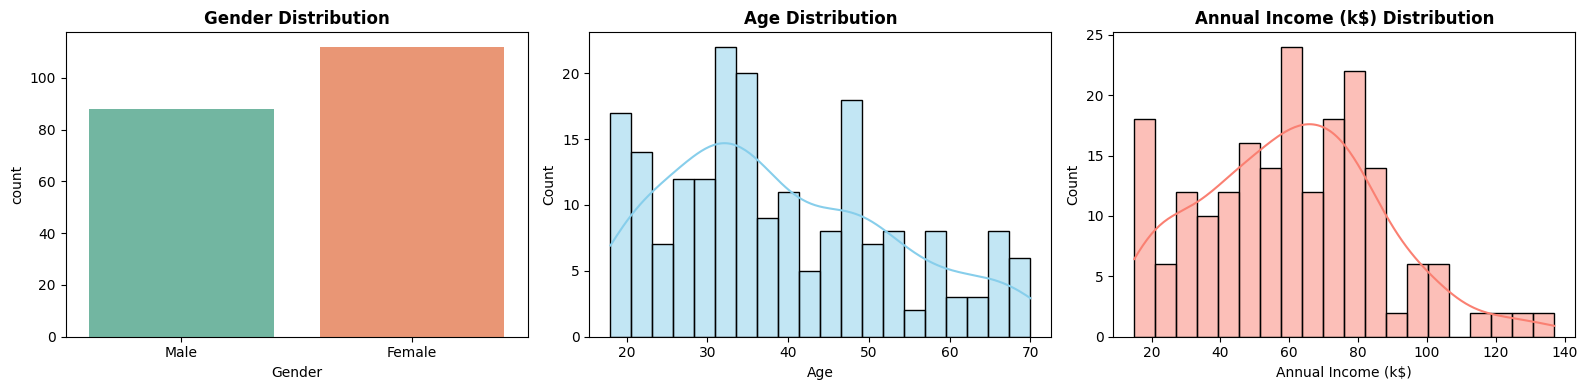

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Gender breakdown
sns.countplot(data=df, x='Gender', hue='Gender', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Gender Distribution', fontsize=12, fontweight='bold')

# 2. Age Distribution
sns.histplot(df['Age'], bins=20, kde=True, color='skyblue', ax=axes[1])
axes[1].set_title('Age Distribution', fontsize=12, fontweight='bold')

# 3. Income Distribution
sns.histplot(df['Annual Income (k$)'], bins=20, kde=True, color='salmon', ax=axes[2])
axes[2].set_title('Annual Income (k$) Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


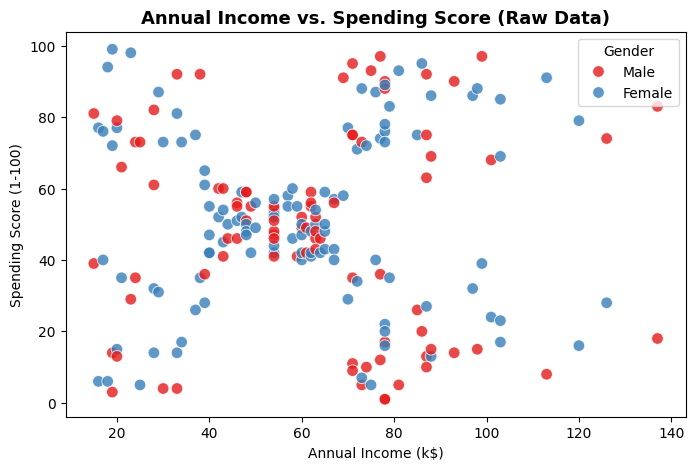

In [5]:
# 2D Relationship: Annual Income vs Spending Score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=70,
    alpha=0.8,
    palette='Set1'
)
plt.title('Annual Income vs. Spending Score (Raw Data)', fontsize=13, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


## 3. Finding the Optimal Number of Clusters (k)

We evaluate $k \in [2, 10]$ using two complementary unsupervised techniques:
1. **The Elbow Method (Inertia / Within-Cluster Sum of Squares - WCSS)**: Identifies the point where additional clusters yield diminishing returns in compactness.
2. **The Silhouette Score**: Measures how similar an object is to its own cluster compared to neighboring clusters (ranging from -1 to +1).


In [6]:
# Select features for customer persona clustering
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil = silhouette_score(X, labels)
    silhouettes.append(sil)

metrics_df = pd.DataFrame({'k': list(k_range), 'Inertia (WCSS)': inertias, 'Silhouette Score': silhouettes})
display(metrics_df.round(4))


,k,Inertia (WCSS),Silhouette Score
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


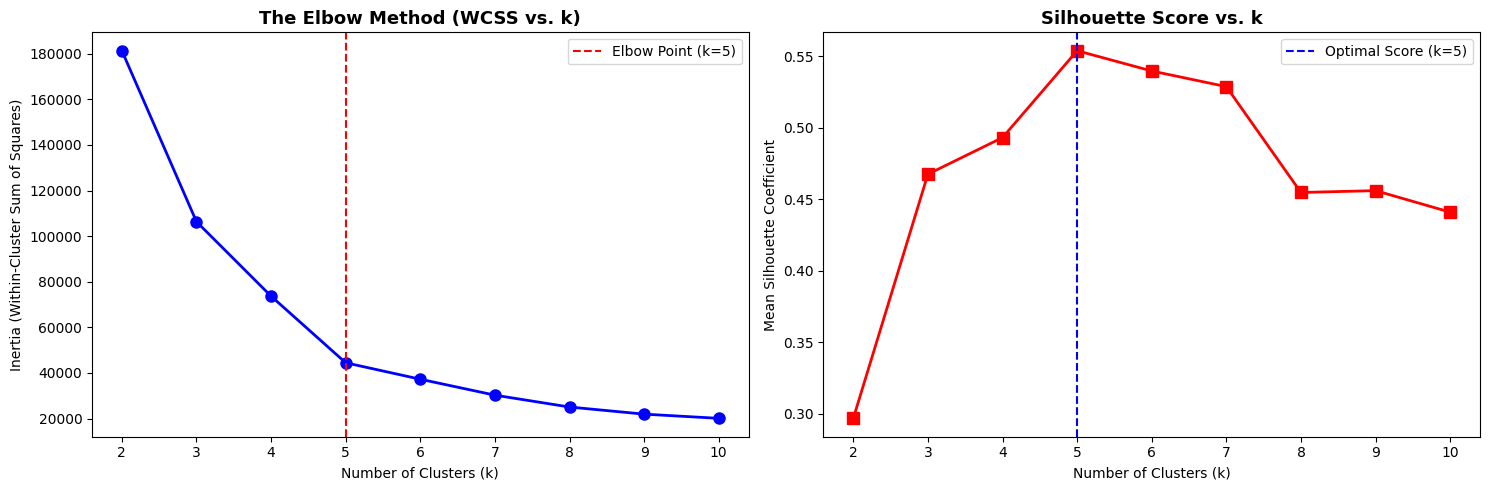

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Elbow Curve
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('The Elbow Method (WCSS vs. k)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].axvline(x=5, color='red', linestyle='--', label='Elbow Point (k=5)')
axes[0].legend()

# 2. Silhouette Score Curve
axes[1].plot(k_range, silhouettes, 'rs-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score vs. k', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Mean Silhouette Coefficient')
axes[1].axvline(x=5, color='blue', linestyle='--', label='Optimal Score (k=5)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Final K-Means Model Training (k=5)

Both the **Elbow Method** and the **Silhouette Score (peak = 0.5539)** confirm that **$k=5$** is the optimal number of behavioral segments.


In [8]:
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

centroids = kmeans.cluster_centers_
print("Cluster Centroids (Annual Income, Spending Score):\n", centroids)


Cluster Centroids (Annual Income, Spending Score):
 [[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


## 5. Visualizing the 5 Customer Segments (2D Scatter Plot)


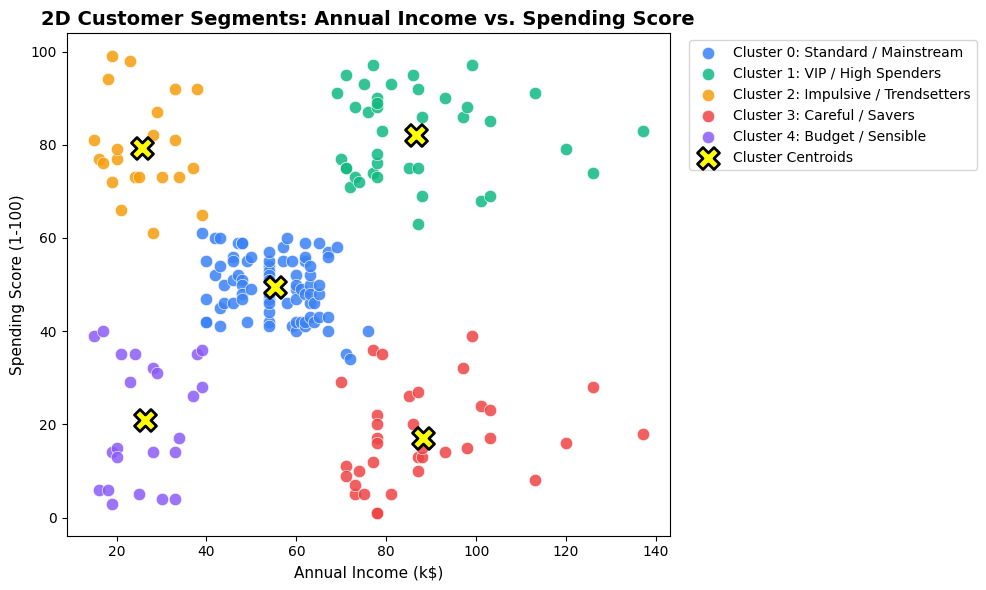

In [9]:
# Dynamically assign personas based on centroid positions to prevent cluster-index mismatch
persona_mapping = {}
for idx, (inc, score) in enumerate(centroids):
    if inc > 65 and score > 60:
        persona_mapping[idx] = 'VIP / High Spenders'
    elif inc > 65 and score < 40:
        persona_mapping[idx] = 'Careful / Savers'
    elif inc < 45 and score > 60:
        persona_mapping[idx] = 'Impulsive / Trendsetters'
    elif inc < 45 and score < 40:
        persona_mapping[idx] = 'Budget / Sensible'
    else:
        persona_mapping[idx] = 'Standard / Mainstream'

df['Persona'] = df['Cluster'].map(persona_mapping)

palette = ['#3B82F6', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6']

plt.figure(figsize=(10, 6))

for cluster_id in range(optimal_k):
    cluster_data = df[df['Cluster'] == cluster_id]
    plt.scatter(
        cluster_data['Annual Income (k$)'],
        cluster_data['Spending Score (1-100)'],
        s=80,
        color=palette[cluster_id],
        label=f"Cluster {cluster_id}: {persona_mapping[cluster_id]}",
        alpha=0.85,
        edgecolor='w',
        linewidth=0.5
    )

# Plot cluster centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,
    c='yellow',
    marker='X',
    edgecolor='black',
    linewidth=2,
    label='Cluster Centroids'
)

plt.title('2D Customer Segments: Annual Income vs. Spending Score', fontsize=14, fontweight='bold')
plt.xlabel('Annual Income (k$)', fontsize=11)
plt.ylabel('Spending Score (1-100)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 6. Cluster Profiling and Strategic Business Recommendations


In [10]:
cluster_profile = df.groupby('Persona').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).rename(columns={'CustomerID': 'Customer Count'}).round(1)

cluster_profile['Share (%)'] = (cluster_profile['Customer Count'] / len(df) * 100).round(1)
display(cluster_profile)


,Customer Count,Age,Annual Income (k$),Spending Score (1-100),Share (%)
Persona,,,,,
Budget / Sensible,23,45.2,26.3,20.9,11.5
Careful / Savers,35,41.1,88.2,17.1,17.5
Impulsive / Trendsetters,22,25.3,25.7,79.4,11.0
Standard / Mainstream,81,42.7,55.3,49.5,40.5
VIP / High Spenders,39,32.7,86.5,82.1,19.5


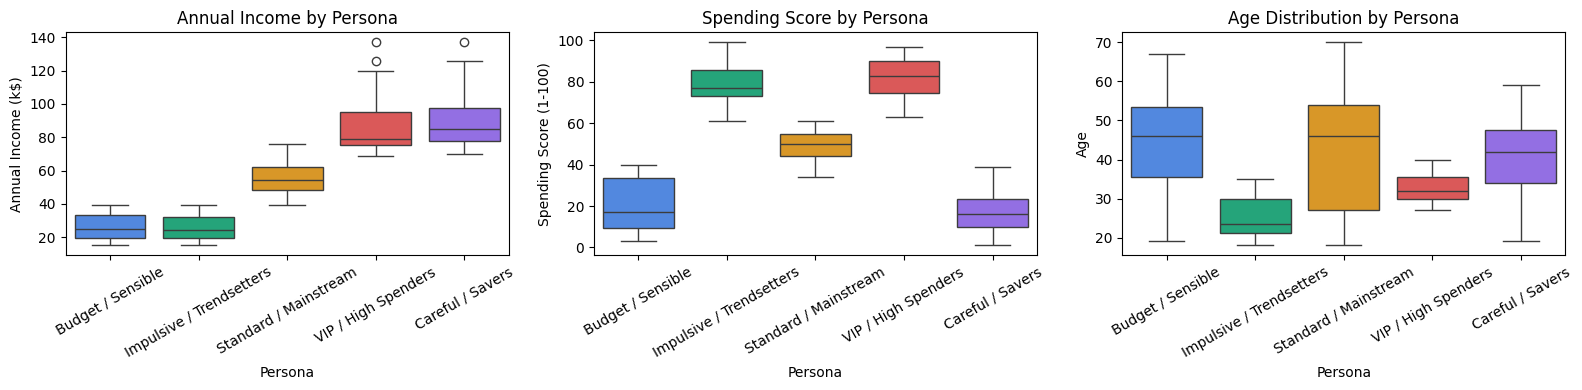

In [11]:
personas = list(df['Persona'].unique())
palette_dict = {p: palette[i % len(palette)] for i, p in enumerate(personas)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x='Persona', y='Annual Income (k$)', hue='Persona', palette=palette_dict, legend=False, ax=axes[0])
axes[0].set_title('Annual Income by Persona')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='Persona', y='Spending Score (1-100)', hue='Persona', palette=palette_dict, legend=False, ax=axes[1])
axes[1].set_title('Spending Score by Persona')
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='Persona', y='Age', hue='Persona', palette=palette_dict, legend=False, ax=axes[2])
axes[2].set_title('Age Distribution by Persona')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 7. Model Serialization for Streamlit Deployment


In [12]:
# Persona descriptions and retail marketing strategies
persona_details = {
    'VIP / High Spenders': {
        'tag': '🎯 Prime Target',
        'desc': 'High income and high spending appetite. Represents the most lucrative customer group.',
        'strategy': 'Promote premium collections, private sales events, and personalized loyalty tiers.'
    },
    'Careful / Savers': {
        'tag': '💼 High Wealth Savers',
        'desc': 'High income but conservative spending patterns. They prioritize quality and value.',
        'strategy': 'Focus on high-durability products, warranties, and educational value propositions.'
    },
    'Standard / Mainstream': {
        'tag': '🛒 Core Base',
        'desc': 'Moderate income with balanced spending behavior. Forms the volume backbone.',
        'strategy': 'Run seasonal discounts, cross-selling bundles, and membership retention rewards.'
    },
    'Impulsive / Trendsetters': {
        'tag': '⚡ Trend Seekers',
        'desc': 'Modest income with disproportionately high spending. Strong preference for trendy goods.',
        'strategy': 'Engage via social media influencers, flash sales, and flexible payment plans.'
    },
    'Budget / Sensible': {
        'tag': '🏷️ Price Sensitive',
        'desc': 'Lower income and low spending propensity. Highly price-conscious.',
        'strategy': 'Offer coupons, clearance promotions, and essential product bundles.'
    }
}

# Save the trained KMeans model and metadata for Streamlit
model_payload = {
    'model': kmeans,
    'features': features,
    'centroids': centroids,
    'persona_mapping': persona_mapping,
    'persona_details': persona_details,
    'data': df
}

joblib.dump(model_payload, 'kmeans_model.joblib')
print("Model payload successfully exported to 'kmeans_model.joblib'")

# Test predicting persona for a new shopper with explicit feature names
test_shopper = pd.DataFrame([[85, 80]], columns=features) # $85k income, 80 spending score
predicted_cluster = kmeans.predict(test_shopper)[0]
print(f"Test Shopper (Income: $85k, Score: 80) -> {persona_mapping[predicted_cluster]}")


Model payload successfully exported to 'kmeans_model.joblib'
Test Shopper (Income: $85k, Score: 80) -> VIP / High Spenders
